# Data mentioned in the text of the Polity section
Every number cited in the section *Linking individuals to polities* and in its *Technical Validation*, recomputed from the database, the life-stage parquets and the benchmark files, or read from the notebook that computes it. Each cell names the paragraph, table or figure it supports.

In [1]:
import json
import sys
from pathlib import Path

import duckdb
import polars as pl
from shapely import STRtree, make_valid, points
from shapely.geometry import shape

sys.path.insert(0, '../notebooks_analysis')
from style import show_table

ROOT = Path.cwd().resolve()
while not (ROOT / '.git').exists():
    ROOT = ROOT.parent

DB_PATH = ROOT / 'data' / 'cultura' / 'cultura_enriched_v3.2.duckdb'  # read only
STAGES_EXPORT = ROOT / 'data' / 'enriched_parquets' / 'individual_life_stage_polities'
CLIOPATRIA = ROOT / 'data' / 'cliopatria_data' / 'cliopatria_V2' / 'cliopatria_polities_only_v3.geojson'
LIFE_LOCATIONS = ROOT / 'data' / 'raw_data_from_wikidata' / 'wikidata_extraction_scripts_v2' / 'life_locations'
BENCHMARK = ROOT / 'notebooks' / 'notebooks_polity_validation' / 'data'
STAGES = {'pre_active': 'Pre-active life', 'active': 'Active life', 'post_active': 'Post-active life'}

connection = duckdb.connect(str(DB_PATH), read_only=True)
features = json.loads(CLIOPATRIA.read_text())['features']

## Wikidata location fields (paragraph 1 and Table 1)
Individuals holding at least one value in each of the eight location fields, as a share of all individuals, and the share of those individuals with at least one value that can be placed on a map. Places are placed by their own coordinates (Place table); employers and schools by the coordinates of their location (Institution table); positions held by their jurisdiction (P1001) when it has coordinates.

In [2]:
total = connection.sql('SELECT count(*) FROM individual').fetchone()[0]
PLACE_FIELDS = {'Place of birth (P19)': '[place_of_birth.entity.qid]', 'Place of death (P20)': '[place_of_death.entity.qid]',
                'Country of citizenship (P27)': 'list_transform(country_of_citizenship, v -> v.entity.qid)',
                'Work location (P937)': 'list_transform(work_location, v -> v.entity.qid)',
                'Residence (P551)': 'list_transform(residence, v -> v.entity.qid)'}
INSTITUTION_FIELDS = {'Employer (P108)': 'employer', 'Educated at (P69)': 'educated_at'}


def coverage(field, values, located):
    return connection.sql(f'''
        WITH held AS (SELECT entity.qid AS person, unnest(list_filter({values}, v -> v IS NOT NULL)) AS target FROM individual)
        SELECT '{field}' AS field, count(DISTINCT person) AS individuals,
               count(DISTINCT person) FILTER (WHERE target IN (SELECT qid FROM {located})) AS placed
        FROM held''').pl()


connection.sql('CREATE TEMP TABLE placed_places AS SELECT entity.qid AS qid FROM place WHERE coordinates.latitude IS NOT NULL')
connection.sql('''CREATE TEMP TABLE placed_institutions AS
    SELECT institution.entity.qid AS qid FROM institution
    WHERE institution.location.entity.qid IN (SELECT qid FROM placed_places)''')
rows = [coverage(f, v, 'placed_places') for f, v in PLACE_FIELDS.items()]
rows += [coverage(f, f'list_transform({c}, v -> v.entity.qid)', 'placed_institutions') for f, c in INSTITUTION_FIELDS.items()]

targets = json.loads((LIFE_LOCATIONS / 'targets.json').read_text())
placed_place_qids = set(connection.sql('SELECT qid FROM placed_places').pl()['qid'])
connection.register('placed_positions', pl.DataFrame({'qid': [q for q, t in targets.items()
                    if any(c or j in placed_place_qids for j, c in (t.get('jurisdiction') or {}).items())]}))
rows.append(coverage('Position held (P39)', 'list_transform(position_held, v -> v.position.qid)', 'placed_positions'))

fields = (pl.concat(rows)
          .with_columns(**{'Individuals (% of all)': (100 * pl.col('individuals') / total).round(1),
                           'Placeable (% of holders)': (100 * pl.col('placed') / pl.col('individuals')).round(1)})
          .sort('individuals', descending=True))
print(f'{total:,} individuals')
fields

13,002,897 individuals


field,individuals,placed,Individuals (% of all),Placeable (% of holders)
str,i64,i64,f64,f64
"""Country of citizenship (P27)""",5570031,5564361,42.8,99.9
"""Place of birth (P19)""",3724787,3703529,28.6,99.4
"""Educated at (P69)""",2484510,2432040,19.1,97.9
"""Place of death (P20)""",1585483,1578578,12.2,99.6
"""Employer (P108)""",1558250,1507750,12.0,96.8
"""Position held (P39)""",979289,651632,7.5,66.5
"""Work location (P937)""",452295,450660,3.5,99.6
"""Residence (P551)""",355609,334890,2.7,94.2


### Table 1: Wikidata location fields and their rank per life stage
Coverage from the cell above; for each stage, the rank at which the field is tried (1 = first), read from `RULES` in `01_life_stage_polities_export.py`. Ranks in bold give a certain assignment, the others an unsure one.

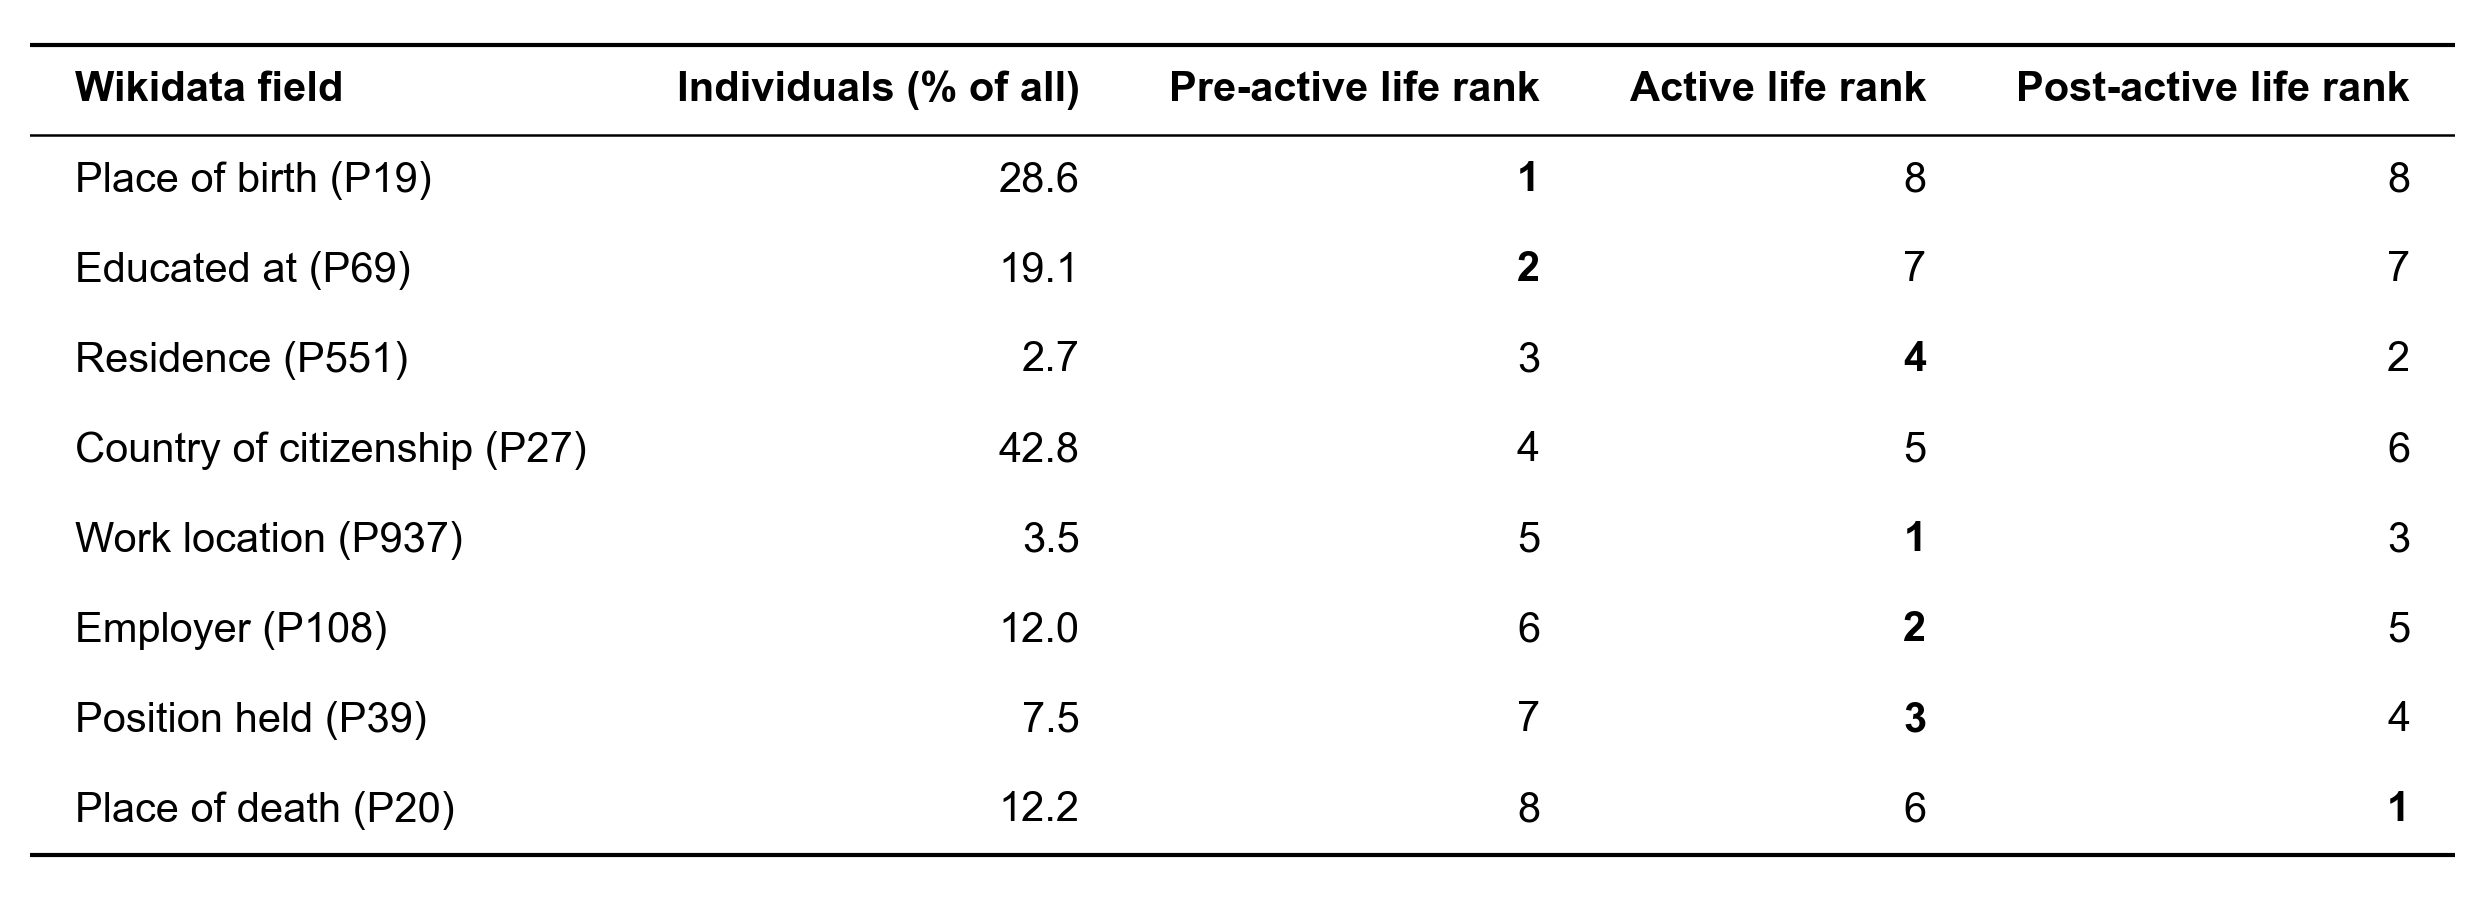

In [3]:
from importlib import import_module

sys.path.insert(0, str(ROOT / 'scripts' / '4-database_enrichment' / '02_notebooks_polity'))
RULES = import_module('01_life_stage_polities_export').RULES
LABELS = {'place_of_birth': 'Place of birth (P19)', 'educated_at': 'Educated at (P69)', 'residence': 'Residence (P551)',
          'country_of_citizenship': 'Country of citizenship (P27)', 'work_location': 'Work location (P937)',
          'employer': 'Employer (P108)', 'position_held': 'Position held (P39)', 'place_of_death': 'Place of death (P20)'}

RANKS = {stage: f'{label} rank' for stage, label in STAGES.items()}
priority = pl.DataFrame([{'field': LABELS[source], 'stage': RANKS[stage], 'rank': rank, 'certain': certainty == 'certain'}
                         for stage, rules in RULES.items() for rank, (source, certainty) in enumerate(rules, 1)])
table_1 = (fields.select(pl.col('field').alias('Wikidata field'), 'Individuals (% of all)')
           .join(priority.pivot(on='stage', index='field', values='rank').rename({'field': 'Wikidata field'}), on='Wikidata field')
           .sort(pl.col('Wikidata field').cast(pl.Enum([LABELS[source] for source, _ in RULES['pre_active']]))))
assert table_1.height == 8
certain = {(table_1['Wikidata field'].to_list().index(LABELS[source]), RANKS[stage])
           for stage, rules in RULES.items() for source, certainty in rules if certainty == 'certain'}
show_table(table_1, decimals=1, font_size=10, bold_cells=certain)


## Border shapes in Wikidata (paragraph 1)
Share of the distinct places cited in the five place fields that have a geographic shape (P3896) in Wikidata, overall and per field. Items with a shape are queried from the QLever Wikidata endpoint once (retried on errors) and cached in `life_locations/items_with_shape_P3896.json`; delete the cache to refresh it.

In [4]:
import time
import urllib.parse
import urllib.request

SHAPE_CACHE = LIFE_LOCATIONS / 'items_with_shape_P3896.json'


def fetch_shaped(tries=5):
    query = 'PREFIX wdt: <http://www.wikidata.org/prop/direct/> SELECT DISTINCT ?item WHERE { ?item wdt:P3896 ?shape }'
    request = urllib.request.Request('https://qlever.dev/api/wikidata', data=urllib.parse.urlencode({'query': query}).encode(),
                                     headers={'Accept': 'text/tab-separated-values'})
    for attempt in range(tries):
        try:
            lines = urllib.request.urlopen(request, timeout=300).read().decode().splitlines()[1:]
            return sorted({line.rsplit('/', 1)[-1].strip('<>') for line in lines})
        except OSError as error:
            wait = min(10 * 2 ** attempt, 60)
            print(f'QLever attempt {attempt + 1} failed ({error}), retrying in {wait} s')
            time.sleep(wait)
    raise RuntimeError('QLever did not answer')


if not SHAPE_CACHE.exists():
    SHAPE_CACHE.write_text(json.dumps(fetch_shaped()))
shaped = pl.DataFrame({'qid': json.loads(SHAPE_CACHE.read_text())})
connection.register('shaped', shaped)
cached_on = time.strftime('%Y-%m-%d', time.localtime(SHAPE_CACHE.stat().st_mtime))
print(f'{shaped.height:,} Wikidata items with a shape (queried {cached_on})')

mentions = ' UNION ALL '.join(f"SELECT '{field}' AS field, unnest(list_filter({values}, v -> v IS NOT NULL)) AS target FROM individual"
                              for field, values in PLACE_FIELDS.items())
connection.sql(f'''
    WITH held AS ({mentions})
    SELECT coalesce(field, 'All place fields') AS field, count(DISTINCT target) AS places,
           round(100 * count(DISTINCT target) FILTER (WHERE target IN (SELECT qid FROM shaped)) / count(DISTINCT target), 1) AS with_shape_pct
    FROM held GROUP BY ROLLUP(field) ORDER BY places DESC''').pl()

69,819 Wikidata items with a shape (queried 2026-11-07)


field,places,with_shape_pct
str,i64,f64
"""All place fields""",349110,4.2
"""Place of birth (P19)""",275526,4.8
"""Place of death (P20)""",130614,5.4
"""Residence (P551)""",58538,7.9
"""Work location (P937)""",44053,10.5
"""Country of citizenship (P27)""",3640,11.9


## Cliopatria (paragraph 1)
Number of polities and territories (a territory is a polity's shape over a span of years), the years covered, and the polities with a parent in the hierarchy (`MemberOf`, or listed in another polity's `Components`).

In [5]:
clio = pl.DataFrame([{k: f['properties'][k] for k in ('Name', 'FromYear', 'ToYear', 'MemberOf', 'Components')} for f in features])
children = {c.strip() for s in clio['Components'] for c in s.split(';') if c.strip()}
with_parent = {n for n, m in zip(clio['Name'], clio['MemberOf']) if m} | children
print(f"{clio['Name'].n_unique():,} polities, {clio.height:,} territories, {clio['FromYear'].min()} to {clio['ToYear'].max()}")
print(f"{len(with_parent & set(clio['Name'])):,} polities with a parent")

1,633 polities, 13,755 territories, -3400 to 2024
336 polities with a parent


## A place that changed hands (paragraph after Table 1)
For the 300 most frequent birthplaces of the database, the Cliopatria polities holding the place each year (smallest of the hierarchy kept). The table lists the places with the most changes of polity within ten consecutive years.

In [6]:
shapes = make_valid([shape(f['geometry']) for f in features])
tree = STRtree(shapes)
props = [f['properties'] for f in features]
parents = {}
for p in props:
    for parent in filter(None, p['MemberOf'].split(';')):
        parents.setdefault(p['Name'], set()).add(parent)
    for child in filter(None, p['Components'].split(';')):
        parents.setdefault(child, set()).add(p['Name'])


def ancestors(name):
    found, todo = set(), [name]
    while todo:
        for parent in parents.get(todo.pop(), ()):
            if parent not in found:
                found.add(parent)
                todo.append(parent)
    return found


top_places = connection.sql('''
    SELECT place.entity.label_en AS place, place.coordinates.longitude AS lon, place.coordinates.latitude AS lat, count(*) AS births
    FROM individual JOIN place ON individual.place_of_birth.entity.qid = place.entity.qid
    WHERE place.coordinates.latitude IS NOT NULL GROUP BY ALL ORDER BY births DESC LIMIT 300''').pl()


def holders(lon, lat):
    hits = [props[i] for i in tree.query(points(lon, lat), predicate='within')]
    years = {}
    for p in hits:
        for year in range(p['FromYear'], p['ToYear'] + 1):
            years.setdefault(year, set()).add(p['Name'])
    return {y: frozenset(n for n in names if not any(n in ancestors(o) for o in names)) for y, names in years.items()}


def most_changes(lon, lat, window=10):
    by_year = holders(lon, lat)
    changes = [y for y in sorted(by_year) if y - 1 in by_year and by_year[y] != by_year[y - 1]]
    best = max(((sum(start <= c < start + window for c in changes), start) for start in changes), default=(0, None))
    sequence = [', '.join(sorted(by_year[y])) for y in range(best[1], best[1] + window) if best[1] is not None and y in by_year] if best[1] else []
    return best[0], best[1], ' → '.join(dict.fromkeys(sequence))


hands = pl.DataFrame([dict(place=r['place'], births=r['births'], **dict(zip(['changes', 'from_year', 'polities'], most_changes(r['lon'], r['lat']))))
                      for r in top_places.iter_rows(named=True)])
with pl.Config(fmt_str_lengths=400, tbl_width_chars=600):
    print(hands.sort('changes', 'births', descending=True).head(8))

shape: (8, 5)
┌─────────────┬────────┬─────────┬───────────┬──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┐
│ place       ┆ births ┆ changes ┆ from_year ┆ polities                                                                                                                             │
│ ---         ┆ ---    ┆ ---     ┆ ---       ┆ ---                                                                                                                                  │
│ str         ┆ i64    ┆ i64     ┆ i64       ┆ str                                                                                                                                  │
╞═════════════╪════════╪═════════╪═══════════╪══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════╡
│ Kyiv        ┆ 7456   ┆ 5       ┆ 1917      ┆ Russian Republic → German Emp

## Life-stage assignment over the whole database (paragraphs on the assignment, Tables 2 and 3)
Individuals with a birth year and an active life (a death year too for the post-active stage), their stages, and per stage the share found, by certainty and by method.

In [7]:
stages = pl.read_parquet(STAGES_EXPORT / 'batch_*.parquet', columns=['qid', 'stage', 'wikidata_field', 'certainty', 'method'])
print(f"{stages['qid'].n_unique():,} individuals ({100 * stages['qid'].n_unique() / total:.1f}% of all), {stages.height:,} stages")
print(stages.group_by('stage').len().sort('stage'))
share = lambda col: (stages.with_columns(pl.col(col).fill_null('not found'))
                     .group_by('stage', col).len()
                     .with_columns(share=(100 * pl.col('len') / pl.col('len').sum().over('stage')).round(1))
                     .pivot(on=col, index='stage', values='share'))
print('Certainty per stage (% of stages)'); print(share('certainty'))
print('Method per stage (% of stages)'); print(share('method'))
found = stages.filter(pl.col('wikidata_field').is_not_null())
per_person = stages.group_by('qid').agg(found=pl.col('wikidata_field').is_not_null().sum(), stages=pl.len())
print(f"{100 * found.height / stages.height:.1f}% of stages found; individuals with at least one stage found: "
      f"{100 * (per_person['found'] > 0).mean():.1f}%; with every stage found: {100 * (per_person['found'] == per_person['stages']).mean():.1f}%")

4,955,108 individuals (38.1% of all), 12,889,933 stages
shape: (3, 2)
┌─────────────┬─────────┐
│ stage       ┆ len     │
│ ---         ┆ ---     │
│ str         ┆ u32     │
╞═════════════╪═════════╡
│ active      ┆ 4955108 │
│ post_active ┆ 2984857 │
│ pre_active  ┆ 4949968 │
└─────────────┴─────────┘
Certainty per stage (% of stages)
shape: (3, 4)
┌─────────────┬──────┬────────┬─────────┐
│ stage       ┆ none ┆ unsure ┆ certain │
│ ---         ┆ ---  ┆ ---    ┆ ---     │
│ str         ┆ f64  ┆ f64    ┆ f64     │
╞═════════════╪══════╪════════╪═════════╡
│ post_active ┆ 29.2 ┆ 34.4   ┆ 36.3    │
│ active      ┆ 28.4 ┆ 47.5   ┆ 24.0    │
│ pre_active  ┆ 28.3 ┆ 21.4   ┆ 50.3    │
└─────────────┴──────┴────────┴─────────┘
Method per stage (% of stages)
shape: (3, 4)
┌─────────────┬─────────────┬───────────┬──────┐
│ stage       ┆ coordinates ┆ not found ┆ URL  │
│ ---         ┆ ---         ┆ ---       ┆ ---  │
│ str         ┆ f64         ┆ f64       ┆ f64  │
╞═════════════╪═════════════╪

71.4% of stages found; individuals with at least one stage found: 71.7%; with every stage found: 71.5%


## Benchmark construction (Technical Validation, Method)
Dictionaries, individuals of Cultura covered by them, the draw, the downloaded biographies and the places extracted (from `01_benchmark_creation`, `02_extract_places_from_biographies` and `03_cliopatria_association`).

In [8]:
population = pl.read_parquet(BENCHMARK / 'population.parquet')
draw = pl.read_csv(BENCHMARK / 'benchmark_cultura.tsv', separator='\t')
texts = json.loads((BENCHMARK / 'benchmark_texts.json').read_text(encoding='utf-8'))
dataset = pl.read_parquet(BENCHMARK / 'benchmark_life_stage_polities.parquet')
print(f"{population['dictionary'].n_unique()} dictionaries, {population['qid'].n_unique():,} Cultura individuals covered")
print(draw['draw'].value_counts())
print(f"{len(texts)} biographies downloaded, from {len({t['dictionary_name'] for t in texts})} dictionaries; "
      f"{len({t['claude_estimated_region'] for t in texts})} regions")
print(dataset.group_by('stage').agg(with_place=pl.col('place').is_not_null().sum(),
                                    with_candidate=(pl.col('candidate_polities').list.len() > 0).sum(),
                                    with_polity=(pl.col('polities').list.len() > 0).sum()))

13 dictionaries, 109,452 Cultura individuals covered
shape: (2, 2)
┌──────────────┬───────┐
│ draw         ┆ count │
│ ---          ┆ ---   │
│ str          ┆ u32   │
╞══════════════╪═══════╡
│ century fill ┆ 249   │
│ quota        ┆ 300   │
└──────────────┴───────┘
547 biographies downloaded, from 13 dictionaries; 11 regions
shape: (3, 4)
┌─────────────┬────────────┬────────────────┬─────────────┐
│ stage       ┆ with_place ┆ with_candidate ┆ with_polity │
│ ---         ┆ ---        ┆ ---            ┆ ---         │
│ str         ┆ u32        ┆ u32            ┆ u32         │
╞═════════════╪════════════╪════════════════╪═════════════╡
│ active      ┆ 528        ┆ 496            ┆ 488         │
│ post_active ┆ 392        ┆ 346            ┆ 333         │
│ pre_active  ┆ 437        ┆ 397            ┆ 384         │
└─────────────┴────────────┴────────────────┴─────────────┘


## Benchmark results (Technical Validation, Results; Tables 5 and 6, Figure 1)
The comparison code of `04_benchmark_results.ipynb` is run as it stands, so the numbers are the notebook's.

In [9]:
results = json.loads((ROOT / 'notebooks' / 'notebooks_polity_validation' / '04_benchmark_results.ipynb').read_text())
exec(''.join(results['cells'][1]['source']).replace('from style import show_table', ''))
by_stage = accuracy(compared, 'stage', 'Stage')
overall = accuracy(compared.with_columns(stage=pl.lit('All stages')), 'stage', 'Stage')
print(pl.concat([by_stage, overall]))
by_region = by_group('region', 'Region')
print(by_region.sort('Overall (%)'))
print(by_group('notability', 'Notability'))
print(f"Not validated: {(~compared['validated']).sum()} of {compared.height} stages")

shape: (3, 4)
┌─────────────┬───────────┬─────────┬──────┐
│ stage       ┆ benchmark ┆ cultura ┆ both │
│ ---         ┆ ---       ┆ ---     ┆ ---  │
│ str         ┆ u32       ┆ u32     ┆ u32  │
╞═════════════╪═══════════╪═════════╪══════╡
│ pre_active  ┆ 397       ┆ 532     ┆ 391  │
│ post_active ┆ 346       ┆ 358     ┆ 236  │
│ active      ┆ 496       ┆ 531     ┆ 486  │
└─────────────┴───────────┴─────────┴──────┘
513 individuals, 1113 stages compared
shape: (4, 3)
┌─────────────┬─────────────┬──────────────┐
│ Stage       ┆ Individuals ┆ Accuracy (%) │
│ ---         ┆ ---         ┆ ---          │
│ str         ┆ u32         ┆ f64          │
╞═════════════╪═════════════╪══════════════╡
│ active      ┆ 486         ┆ 88.1         │
│ pre_active  ┆ 391         ┆ 89.5         │
│ post_active ┆ 236         ┆ 89.4         │
│ All stages  ┆ 513         ┆ 88.9         │
└─────────────┴─────────────┴──────────────┘
shape: (11, 6)
┌───────────────────┬─────────────┬────────────┬────────────────

### Region and century cells (Figure 1)
Region × century cells, the cells below 70% and their size, and the accuracy for individuals born before and after 1500.

In [10]:
grid = compared.group_by('region', 'century').agg(n=pl.col('qid').n_unique(), acc=100 * pl.col('validated').mean())
low = grid.filter(pl.col('acc') < 70)
print(f"{grid.height} cells, median {grid['n'].median():.0f} individuals; {grid.filter(pl.col('acc') >= 90).height} cells at 90% or more")
print(f"{low.height} cells below 70%, largest {low['n'].max()} individuals")
for label, frame in [('born before 1500', compared.filter(pl.col('century') <= 15)), ('born 1500 or later', compared.filter(pl.col('century') > 15))]:
    print(f"{label}: {100 * frame['validated'].mean():.1f}% of {frame.height} stages")

175 cells, median 3 individuals; 105 cells at 90% or more
25 cells below 70%, largest 4 individuals
born before 1500: 87.6% of 631 stages
born 1500 or later: 90.5% of 482 stages
